# Task 2: Movie Rating Prediction
**MyDailyWork Data Science Internship**

Goal: predict a movie's IMDb rating from its genre, director, actors, duration and year.

## Step 1: Import libraries

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

## Step 2: Read the dataset

In [11]:
# Read Dataset  (in Google Colab use: "/content/IMDb Movies India.csv")
df = pd.read_csv("IMDb Movies India.csv", encoding="latin-1")
df.head()

,Name,Year,Duration,Genre,Rating,Votes,Director,Actor 1,Actor 2,Actor 3
0,,NaN,NaN,Drama,NaN,NaN,J.S. Randhawa,Manmauji,Birbal,Rajendra Bhatia
1,#Gadhvi (He thought he was Gandhi),(2019),109 min,Drama,7.0,8,Gaurav Bakshi,Rasika Dugal,Vivek Ghamande,Arvind Jangid
2,#Homecoming,(2021),90 min,"Drama, Musical",NaN,NaN,Soumyajit Majumdar,Sayani Gupta,Plabita Borthakur,Roy Angana
3,#Yaaram,(2019),110 min,"Comedy, Romance",4.4,35,Ovais Khan,Prateik,Ishita Raj,Siddhant Kapoor
4,...And Once Again,(2010),105 min,Drama,NaN,NaN,Amol Palekar,Rajat Kapoor,Rituparna Sengupta,Antara Mali


In [12]:
df.shape

(15509, 10)

In [13]:
# Missing values in each column
df.isnull().sum()

Name           0
Year         528
Duration    8269
Genre       1877
Rating      7590
Votes       7589
Director     525
Actor 1     1617
Actor 2     2384
Actor 3     3144
dtype: int64

## Step 3: Clean the data

In [14]:
# Year looks like "(2019)"  ->  2019
df["Year"] = df["Year"].astype(str).str.extract(r"(\d{4})")[0].astype(float)

# Duration looks like "109 min"  ->  109
df["Duration"] = df["Duration"].astype(str).str.extract(r"(\d+)")[0].astype(float)

# Votes look like "1,086"  ->  1086
df["Votes"] = pd.to_numeric(df["Votes"].astype(str).str.replace(",", ""), errors="coerce")

In [15]:
# We cannot learn from movies that have no rating, so remove them
df = df.dropna(subset=["Rating"])

# Fill the other missing values
df["Year"] = df["Year"].fillna(df["Year"].median())
df["Duration"] = df["Duration"].fillna(df["Duration"].median())
df["Votes"] = df["Votes"].fillna(df["Votes"].median())
for col in ["Genre", "Director", "Actor 1", "Actor 2", "Actor 3"]:
    df[col] = df[col].fillna("Unknown")

# Votes have huge differences (5 votes vs 500000 votes), so use the log
df["Log Votes"] = np.log1p(df["Votes"])
print("Movies left:", len(df))

Movies left: 7919


## Step 4: Explore the data (charts)

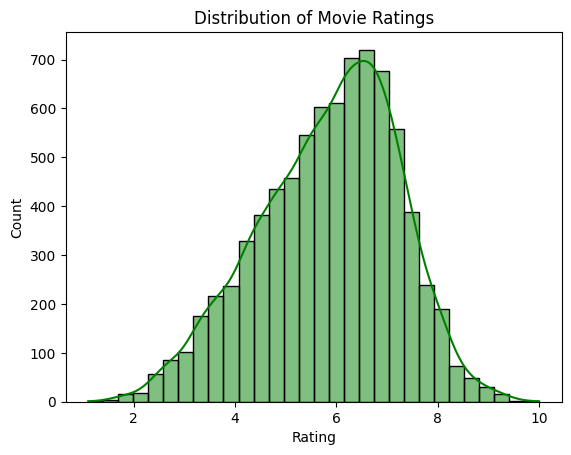

In [16]:
# How are ratings spread?
sns.histplot(df["Rating"], bins=30, kde=True, color="green")
plt.title("Distribution of Movie Ratings")
plt.show()

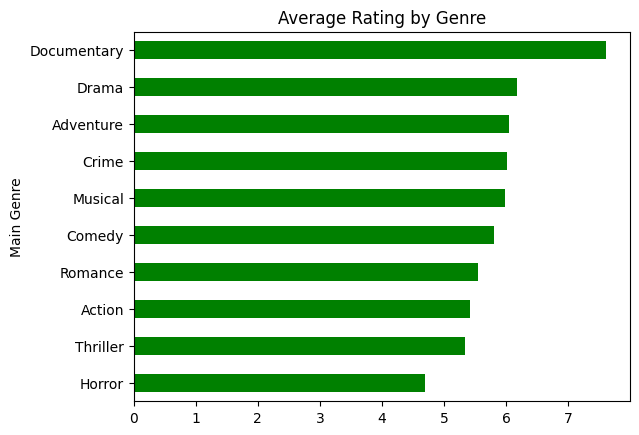

In [17]:
# Average rating of the 10 most common genres
df["Main Genre"] = df["Genre"].str.split(",").str[0].str.strip()
top10 = df["Main Genre"].value_counts().head(10).index
df[df["Main Genre"].isin(top10)].groupby("Main Genre")["Rating"].mean().sort_values().plot(kind="barh", color="green")
plt.title("Average Rating by Genre")
plt.show()

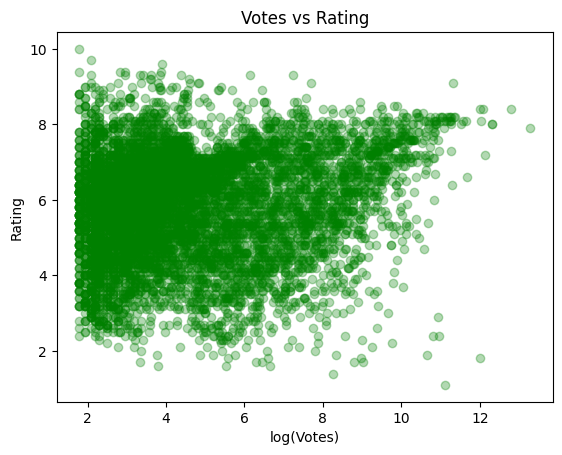

In [18]:
# Do popular movies get better ratings?
plt.scatter(df["Log Votes"], df["Rating"], alpha=0.3, color="green")
plt.xlabel("log(Votes)")
plt.ylabel("Rating")
plt.title("Votes vs Rating")
plt.show()

## Step 5: Make features

In [19]:
# Genre: one 0/1 column for each of the 10 most common genres
top_genres = df["Genre"].str.split(",").explode().str.strip().value_counts().head(10).index.tolist()

for g in top_genres:
    df["G_" + g] = df["Genre"].str.contains(g, regex=False).astype(int)
top_genres

['Drama',
 'Action',
 'Romance',
 'Comedy',
 'Crime',
 'Thriller',
 'Family',
 'Musical',
 'Adventure',
 'Mystery']

In [20]:
# Split the data FIRST (80% train, 20% test)
train, test = train_test_split(df, test_size=0.2, random_state=42)
train = train.copy()
test = test.copy()

**Director and actor names:** there are thousands of names, so we turn each name into a number =
the average rating of that person's movies. For a training movie we leave out its own rating, so the model cannot cheat.

In [21]:
average_rating = train["Rating"].mean()
k = 5    # pulls people with only 1 or 2 movies towards the overall average
name_maps = {}

for col in ["Director", "Actor 1", "Actor 2", "Actor 3"]:
    g = train.groupby(col)["Rating"]
    # training rows: average of the person's OTHER movies
    train[col + " score"] = (g.transform("sum") - train["Rating"] + k * average_rating) / (g.transform("count") - 1 + k)
    # average per person, used for test movies and for the app
    name_maps[col] = (g.sum() + k * average_rating) / (g.count() + k)
    test[col + " score"] = test[col].map(name_maps[col]).fillna(average_rating)

# One score for the three actors together
train["Actors score"] = train[["Actor 1 score", "Actor 2 score", "Actor 3 score"]].mean(axis=1)
test["Actors score"] = test[["Actor 1 score", "Actor 2 score", "Actor 3 score"]].mean(axis=1)

In [22]:
features = ["Year", "Duration", "Log Votes", "Director score", "Actors score"] + ["G_" + g for g in top_genres]

x_train = train[features]
y_train = train["Rating"]
x_test = test[features]
y_test = test["Rating"]

## Step 6: Train two models and compare

In [23]:
lr = LinearRegression()
lr.fit(x_train, y_train)

rf = RandomForestRegressor(n_estimators=100, min_samples_leaf=3, random_state=42, n_jobs=-1)
rf.fit(x_train, y_train)

,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",3
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"m

In [24]:
# Compare: R2 (higher is better), MAE and RMSE (lower is better)
def show(name, y_pred):
    print(name)
    print("  R2   :", round(r2_score(y_test, y_pred), 3))
    print("  MAE  :", round(mean_absolute_error(y_test, y_pred), 3), "(average mistake in rating points)")
    print("  RMSE :", round(mean_squared_error(y_test, y_pred) ** 0.5, 3))

show("Just guess the average", [average_rating] * len(y_test))
show("Linear Regression", lr.predict(x_test))
show("Random Forest", rf.predict(x_test))

Just guess the average
  R2   : -0.002
  MAE  : 1.107 (average mistake in rating points)
  RMSE : 1.365
Linear Regression
  R2   : 0.318
  MAE  : 0.869 (average mistake in rating points)
  RMSE : 1.126
Random Forest
  R2   : 0.392
  MAE  : 0.802 (average mistake in rating points)
  RMSE : 1.063


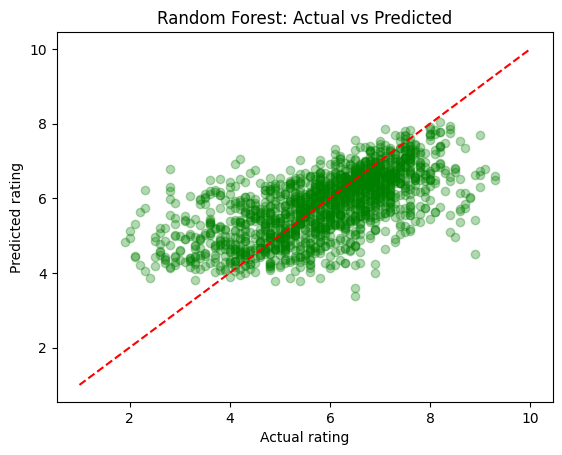

In [25]:
# Actual vs predicted (closer to the red line = better)
y_pred = rf.predict(x_test)
plt.scatter(y_test, y_pred, alpha=0.3, color="green")
plt.plot([1, 10], [1, 10], "r--")
plt.xlabel("Actual rating")
plt.ylabel("Predicted rating")
plt.title("Random Forest: Actual vs Predicted")
plt.show()

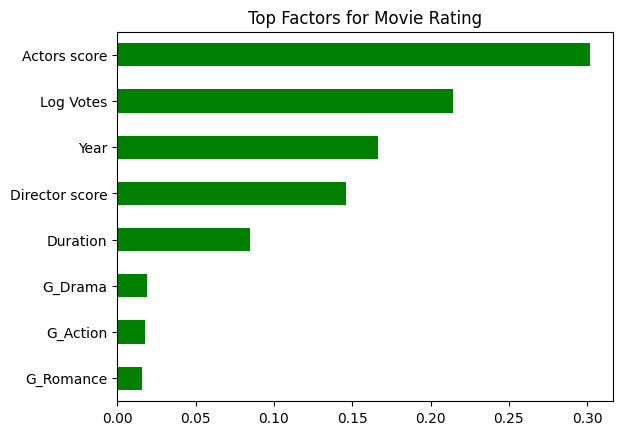

In [26]:
# What matters most?
importance = pd.Series(rf.feature_importances_, index=features).sort_values().tail(8)
importance.plot(kind="barh", color="green")
plt.title("Top Factors for Movie Rating")
plt.show()

## Step 7: A fair test - what if we do NOT know the votes?
Votes only exist AFTER a movie is released. So we train a second model without votes to see how well we can predict BEFORE release.

In [27]:
features_no_votes = [f for f in features if f != "Log Votes"]

rf_no_votes = RandomForestRegressor(n_estimators=100, min_samples_leaf=3, random_state=42, n_jobs=-1)
rf_no_votes.fit(train[features_no_votes], y_train)

show("Random Forest WITH votes", rf.predict(x_test))
show("Random Forest WITHOUT votes", rf_no_votes.predict(test[features_no_votes]))

Random Forest WITH votes
  R2   : 0.392
  MAE  : 0.802 (average mistake in rating points)
  RMSE : 1.063
Random Forest WITHOUT votes
  R2   : 0.301
  MAE  : 0.873 (average mistake in rating points)
  RMSE : 1.14


## Step 8: Predict one movie

In [28]:
one_movie = test.iloc[[0]]
print("Movie    :", one_movie["Name"].values[0])
print("Actual   :", one_movie["Rating"].values[0])
print("Predicted:", round(rf.predict(one_movie[features])[0], 2))

Movie    : Mohabbat Pehli Nazar Mein
Actual   : 3.3
Predicted: 4.96


## Step 9: Save the models (the Streamlit app uses this file)

In [29]:
# Names that appear in 2 or more movies (for the app drop-down lists)
directors = train["Director"].value_counts()
directors = directors[directors >= 2].index.tolist()
actors = pd.concat([train["Actor 1"], train["Actor 2"], train["Actor 3"]]).value_counts()
actors = actors[actors >= 3].index.tolist()

joblib.dump({
    "model": rf, "model_no_votes": rf_no_votes,
    "features": features, "features_no_votes": features_no_votes,
    "top_genres": top_genres, "name_maps": name_maps, "average_rating": average_rating,
    "directors": directors, "actors": actors,
    "year_min": int(df["Year"].min()), "year_max": int(df["Year"].max()),
}, "movie_model.pkl")
print("Models saved!")

Models saved!
